# Preparación de los datos (0.1, 0.2 y 0.4)

**Autora:** Sofía Isabela Sandoval Vásquez · Grupo Taiwan

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por la autora.

In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from datos import cargar_taiwan
from pesos import pesos_ols, pesos_ridge, pesos_knn, pesos_arbol

hp = json.load(open("../resultados/hiperparametros.json"))
hp

{'lambda': 316.2278, 'k': 50, 'max_depth': 4, 'min_samples_leaf': 50}

## 0.1 · Partición y estandarización

80 % de entrenamiento y 20 % de prueba con `random_state=0`. El `StandardScaler` se ajusta solo con el entrenamiento y con él se transforman ambos conjuntos. La variable respuesta es `default` (1 si el cliente cae en mora el mes siguiente).

In [2]:
X_train, X_test, y_train, y_test, sd = cargar_taiwan("../data/taiwan_credit.csv")

pd.DataFrame({
    "filas": [len(X_train), len(X_test)],
    "variables": [X_train.shape[1], X_test.shape[1]],
    "tasa de mora": [y_train.mean(), y_test.mean()],
    "media máx. |X|": [X_train.mean().abs().max(), X_test.mean().abs().max()],
    "DE promedio de X": [X_train.std(ddof=0).mean(), X_test.std(ddof=0).mean()],
}, index=["entrenamiento", "prueba"]).round(4)

,filas,variables,tasa de mora,media máx. |X|,DE promedio de X
entrenamiento,24000,23,0.2225,0.0000,1.0000
prueba,6000,23,0.2162,0.0276,1.0098


En entrenamiento las variables quedan con media 0 y desviación estándar 1. En prueba quedan cerca, pero no exactas, porque se transformaron con la media y la desviación del entrenamiento (así no se filtra información de prueba).

## 0.4 · Desviación estándar antes de estandarizar

Se guarda en `resultados/sd_taiwan.csv` para la Parte 4.

In [3]:
sd.to_csv("../resultados/sd_taiwan.csv")
sd.sort_values(ascending=False).to_frame().style.format("{:,.2f}")

,sd
LIMIT_BAL,"129,479.70"
BILL_AMT1,"73,525.22"
BILL_AMT2,"70,960.57"
BILL_AMT3,"69,505.30"
BILL_AMT4,"64,153.27"
BILL_AMT5,"60,673.60"
BILL_AMT6,"59,424.68"
PAY_AMT2,"23,436.62"
PAY_AMT6,"17,606.70"
PAY_AMT3,"17,186.82"


Las variables de montos en dólares taiwaneses (`LIMIT_BAL`, `BILL_AMT1`–`BILL_AMT6` y `PAY_AMT1`–`PAY_AMT6`) tienen desviaciones estándar entre 15 000 y 130 000, mientras que las variables de estado de pago (`PAY_0`–`PAY_6`), las categóricas (`SEX`, `EDUCATION`, `MARRIAGE`) y la edad tienen desviaciones de 0.5 a 9. En escala cruda, cualquier distancia queda dominada por los montos, en particular por `LIMIT_BAL`; esto es lo que se estudia en la Parte 4.

## 0.2 · Un voto ponderado de etiquetas 0/1 como probabilidad

Se ajustan los cinco regresores con los hiperparámetros de `resultados/hiperparametros.json` y se revisa el rango de sus predicciones en prueba.

In [4]:
modelos = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=hp["lambda"]),
    "k-NN": KNeighborsRegressor(n_neighbors=hp["k"]),
    "Árbol": DecisionTreeRegressor(max_depth=hp["max_depth"], random_state=0),
    "Bosque": RandomForestRegressor(n_estimators=200, min_samples_leaf=hp["min_samples_leaf"],
                                    max_features=0.33, bootstrap=False, random_state=0, n_jobs=-1),
}
pred = {nombre: m.fit(X_train, y_train).predict(X_test) for nombre, m in modelos.items()}

pd.DataFrame({
    "mínimo": {k: p.min() for k, p in pred.items()},
    "máximo": {k: p.max() for k, p in pred.items()},
    "predicciones < 0": {k: (p < 0).sum() for k, p in pred.items()},
    "predicciones > 1": {k: (p > 1).sum() for k, p in pred.items()},
}).round(3)

,mínimo,máximo,predicciones < 0,predicciones > 1
OLS,-0.372,1.286,432,4
Ridge,-0.352,1.276,426,4
k-NN,0.000,0.880,0,0
Árbol,0.100,0.787,0,0
Bosque,0.008,0.887,0,0


Los pesos de cuatro de los modelos se calculan con `src/pesos.py` sobre las primeras 500 filas de prueba (los del bosque los calcula la Parte 1.4).

In [5]:
q = X_test.iloc[:500]
W = {
    "OLS": pesos_ols(X_train, q),
    "Ridge": pesos_ridge(X_train, q, hp["lambda"]),
    "k-NN": pesos_knn(modelos["k-NN"], q, len(X_train)),
    "Árbol": pesos_arbol(modelos["Árbol"], X_train, q),
}
for nombre, w in W.items():
    assert np.abs(w @ y_train - modelos[nombre].predict(q)).max() < 1e-8

pd.DataFrame({
    "Σw mínima": {k: w.sum(1).min() for k, w in W.items()},
    "Σw máxima": {k: w.sum(1).max() for k, w in W.items()},
    "peso mínimo": {k: w.min() for k, w in W.items()},
    "pesos negativos por consulta (prom.)": {k: (w < 0).sum(1).mean() for k, w in W.items()},
}).round(4)

,Σw mínima,Σw máxima,peso mínimo,pesos negativos por consulta (prom.)
OLS,1.0,1.0,-0.0218,9187.708
Ridge,1.0,1.0,-0.0169,9097.552
k-NN,1.0,1.0,0.0000,0.000
Árbol,1.0,1.0,0.0000,0.000


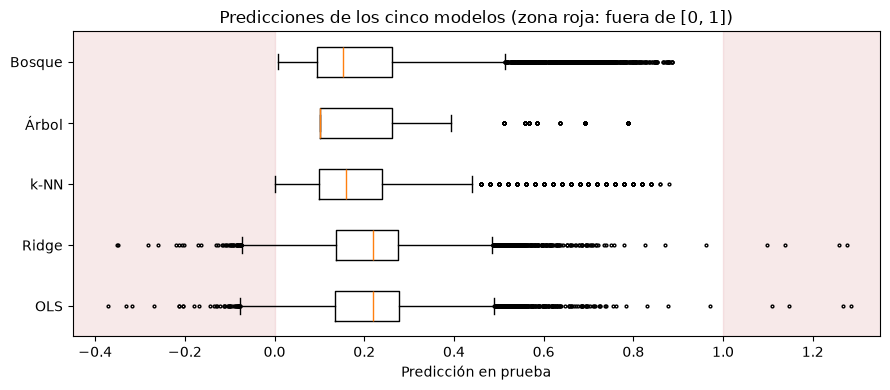

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(list(pred.values()), tick_labels=list(pred.keys()), orientation="horizontal", flierprops={"markersize": 2})
ax.axvspan(-0.5, 0, color="#C44E52", alpha=0.12)
ax.axvspan(1, 1.5, color="#C44E52", alpha=0.12)
ax.set(xlim=(-0.45, 1.35), xlabel="Predicción en prueba", title="Predicciones de los cinco modelos (zona roja: fuera de [0, 1])")
plt.tight_layout()
plt.savefig("../figs/parte0_predicciones_por_modelo.png", dpi=150)
plt.show()

> **Pregunta 0.2 (a).** ¿Por qué un voto ponderado de etiquetas 0/1 se puede leer como una probabilidad?

Si $y_i \in \{0, 1\}$, la predicción $\hat y(x) = \sum_i w_i(x)\, y_i = \sum_{i:\, y_i = 1} w_i(x)$ es el peso total que reciben los clientes que cayeron en mora. Cuando los pesos son no negativos y suman 1, ese peso total es la fracción (ponderada) de clientes parecidos a $x$ que cayeron en mora, es decir, una estimación de $P(y = 1 \mid x)$. Por ejemplo, en k-NN con $k = 30$, si 9 de los 30 vecinos cayeron en mora, la predicción es 0.3.

> **Pregunta 0.2 (b).** ¿Qué condición sobre los pesos hace falta para que quede entre 0 y 1, y cuáles de los cinco modelos la cumplen?

Hace falta que $w_i(x) \ge 0$ para todo $i$ y que $\sum_i w_i(x) = 1$: así $\hat y(x)$ es una combinación convexa de ceros y unos y no puede salir de $[0, 1]$. k-NN, el árbol y el bosque la cumplen por construcción (sus pesos son $1/k$ o $1/\text{tamaño de la hoja}$, promediados entre árboles en el caso del bosque), y en la tabla ninguna de sus predicciones sale del intervalo. OLS y ridge no la cumplen: sus pesos suman 1, pero alrededor de 9 000 de los 24 000 pesos de cada consulta son negativos, y por eso 436 (OLS) y 430 (ridge) de las 6 000 predicciones de prueba quedan por debajo de 0 o por encima de 1, lo cual no se puede leer como probabilidad.